# DreamerV3: a world model that imagines in pixels

[![Open in Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/latent-horizon/pytorch-world/blob/main/examples/action/dreamerv3.ipynb)

[DreamerV3](https://arxiv.org/abs/2301.04104) ([code](https://github.com/danijar/dreamerv3)) is the reference world model that is *not* a JEPA: a recurrent state-space model learned by reconstructing every frame, with a recurrent state and categorical latents, a prior that predicts the next latent without the frame, and an actor-critic trained on imagined trajectories. Because it has a decoder, everything it imagines can be looked at. Here it learns Two-Rooms from the same reward-free, random-action episodes as the [main benchmark](../comparisons/main_benchmark.ipynb), plans toward goal images with CEM on its model state, and, on hindsight goals, trains its actor.

In [1]:
import importlib.util

if importlib.util.find_spec("torch_world") is None:  # on Colab
    %pip install -q "torch-world[examples]"

In [2]:
import time

import torch
from torch.utils.data import DataLoader

from torch_world import evaluation, plots
from torch_world.datasets import TrajectoryDataset
from torch_world.envs import TwoRooms
from torch_world.models import DreamerV3
from torch_world.planning import CEM

torch.manual_seed(0)
device = "cuda" if torch.cuda.is_available() else "cpu"
EPOCHS = 10

## Data and model
A point wanders through two rooms joined by a door, keeping its previous action 80% of the time: 1024 episodes of 65 steps, no rewards, no expert. Episodes are cut into windows of 17 frames and 16 actions.

The model is small: a 256-unit GRU state, 32 categoricals of 16 classes, a 4-stage CNN encoder and its mirror-image decoder. The paper's smallest preset (8M parameters) has 32×32 categoricals and a wider CNN.

In [3]:
data = TwoRooms(batch_size=1024, device=device).collect(65, generator=torch.Generator().manual_seed(0))
loader = DataLoader(TrajectoryDataset(data, window=17), batch_size=64, shuffle=True, drop_last=True)

model = DreamerV3(action_dim=2).to(device)
print(f"{sum(p.numel() for p in model.parameters() if p.requires_grad) / 1e6:.2f}M parameters")

4.56M parameters


## Train
With no rewards only the world model learns: reconstruction plus the two KL terms, clipped below 1 nat (free bits). Adam with the paper's learning rate and gradient clipping, through `param_groups` and `clip_grad_norm`.

26.8 min


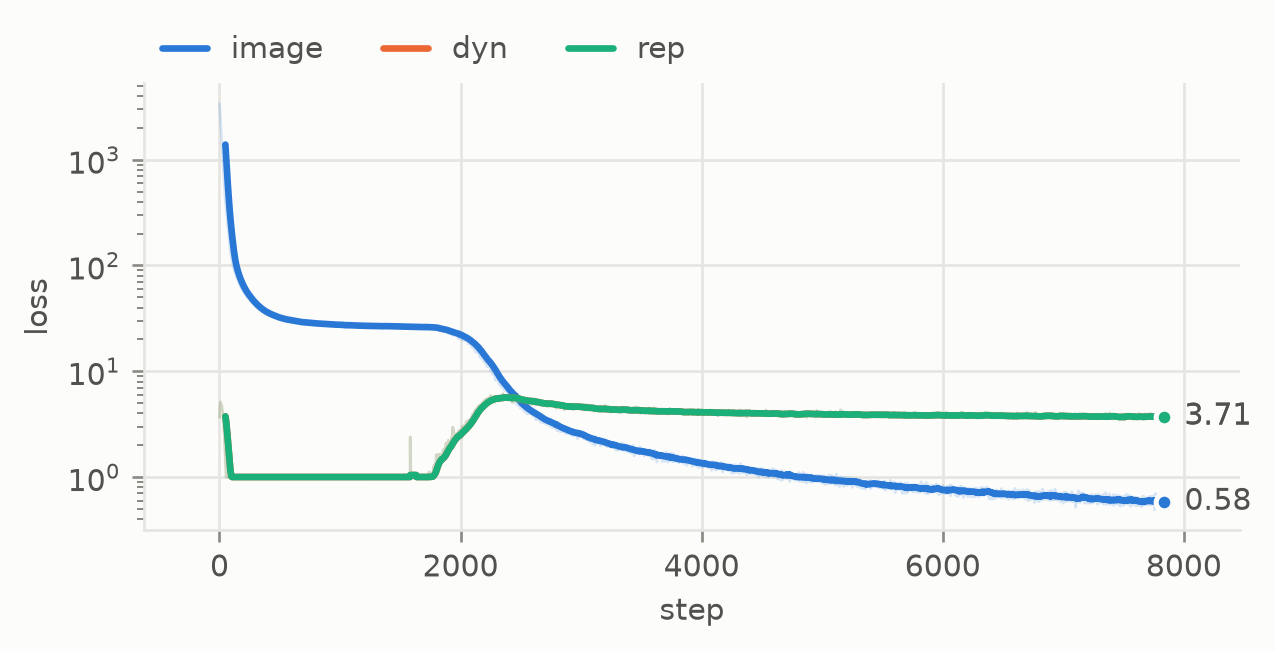

In [4]:
def train(model, epochs, inputs):
    opt = torch.optim.Adam(model.param_groups())
    log = {}
    model.train()
    for _ in range(epochs):
        for batch in loader:
            out = model(*inputs(batch))
            opt.zero_grad()
            out["loss"].backward()
            model.clip_grad_norm()
            opt.step()
            model.update_target()
            for k, v in out.items():
                if k.endswith("_loss"):
                    log.setdefault(k.removesuffix("_loss"), []).append(v.item())
    return log


tic = time.time()
log = train(model, EPOCHS, lambda b: (b["pixels"], b["actions"][:, :-1]))
model.eval()
print(f"{(time.time() - tic) / 60:.1f} min")
plots.curves(log, smooth=50)

## What the model imagines
The decoder is what sets Dreamer apart from the JEPAs: any model state can be turned back into a frame. From the first frame of held-out episodes, the prior unrolls the episode's real actions for 16 steps without seeing another frame; top rows are the real frames, bottom rows the decoded imagination.

pixel MSE per imagined step: 0.0002 0.0001 0.0001 0.0002 0.0002 0.0002 0.0003 0.0004 0.0004 0.0005 0.0002 0.0002 0.0004 0.0003 0.0002 0.0001 0.0001


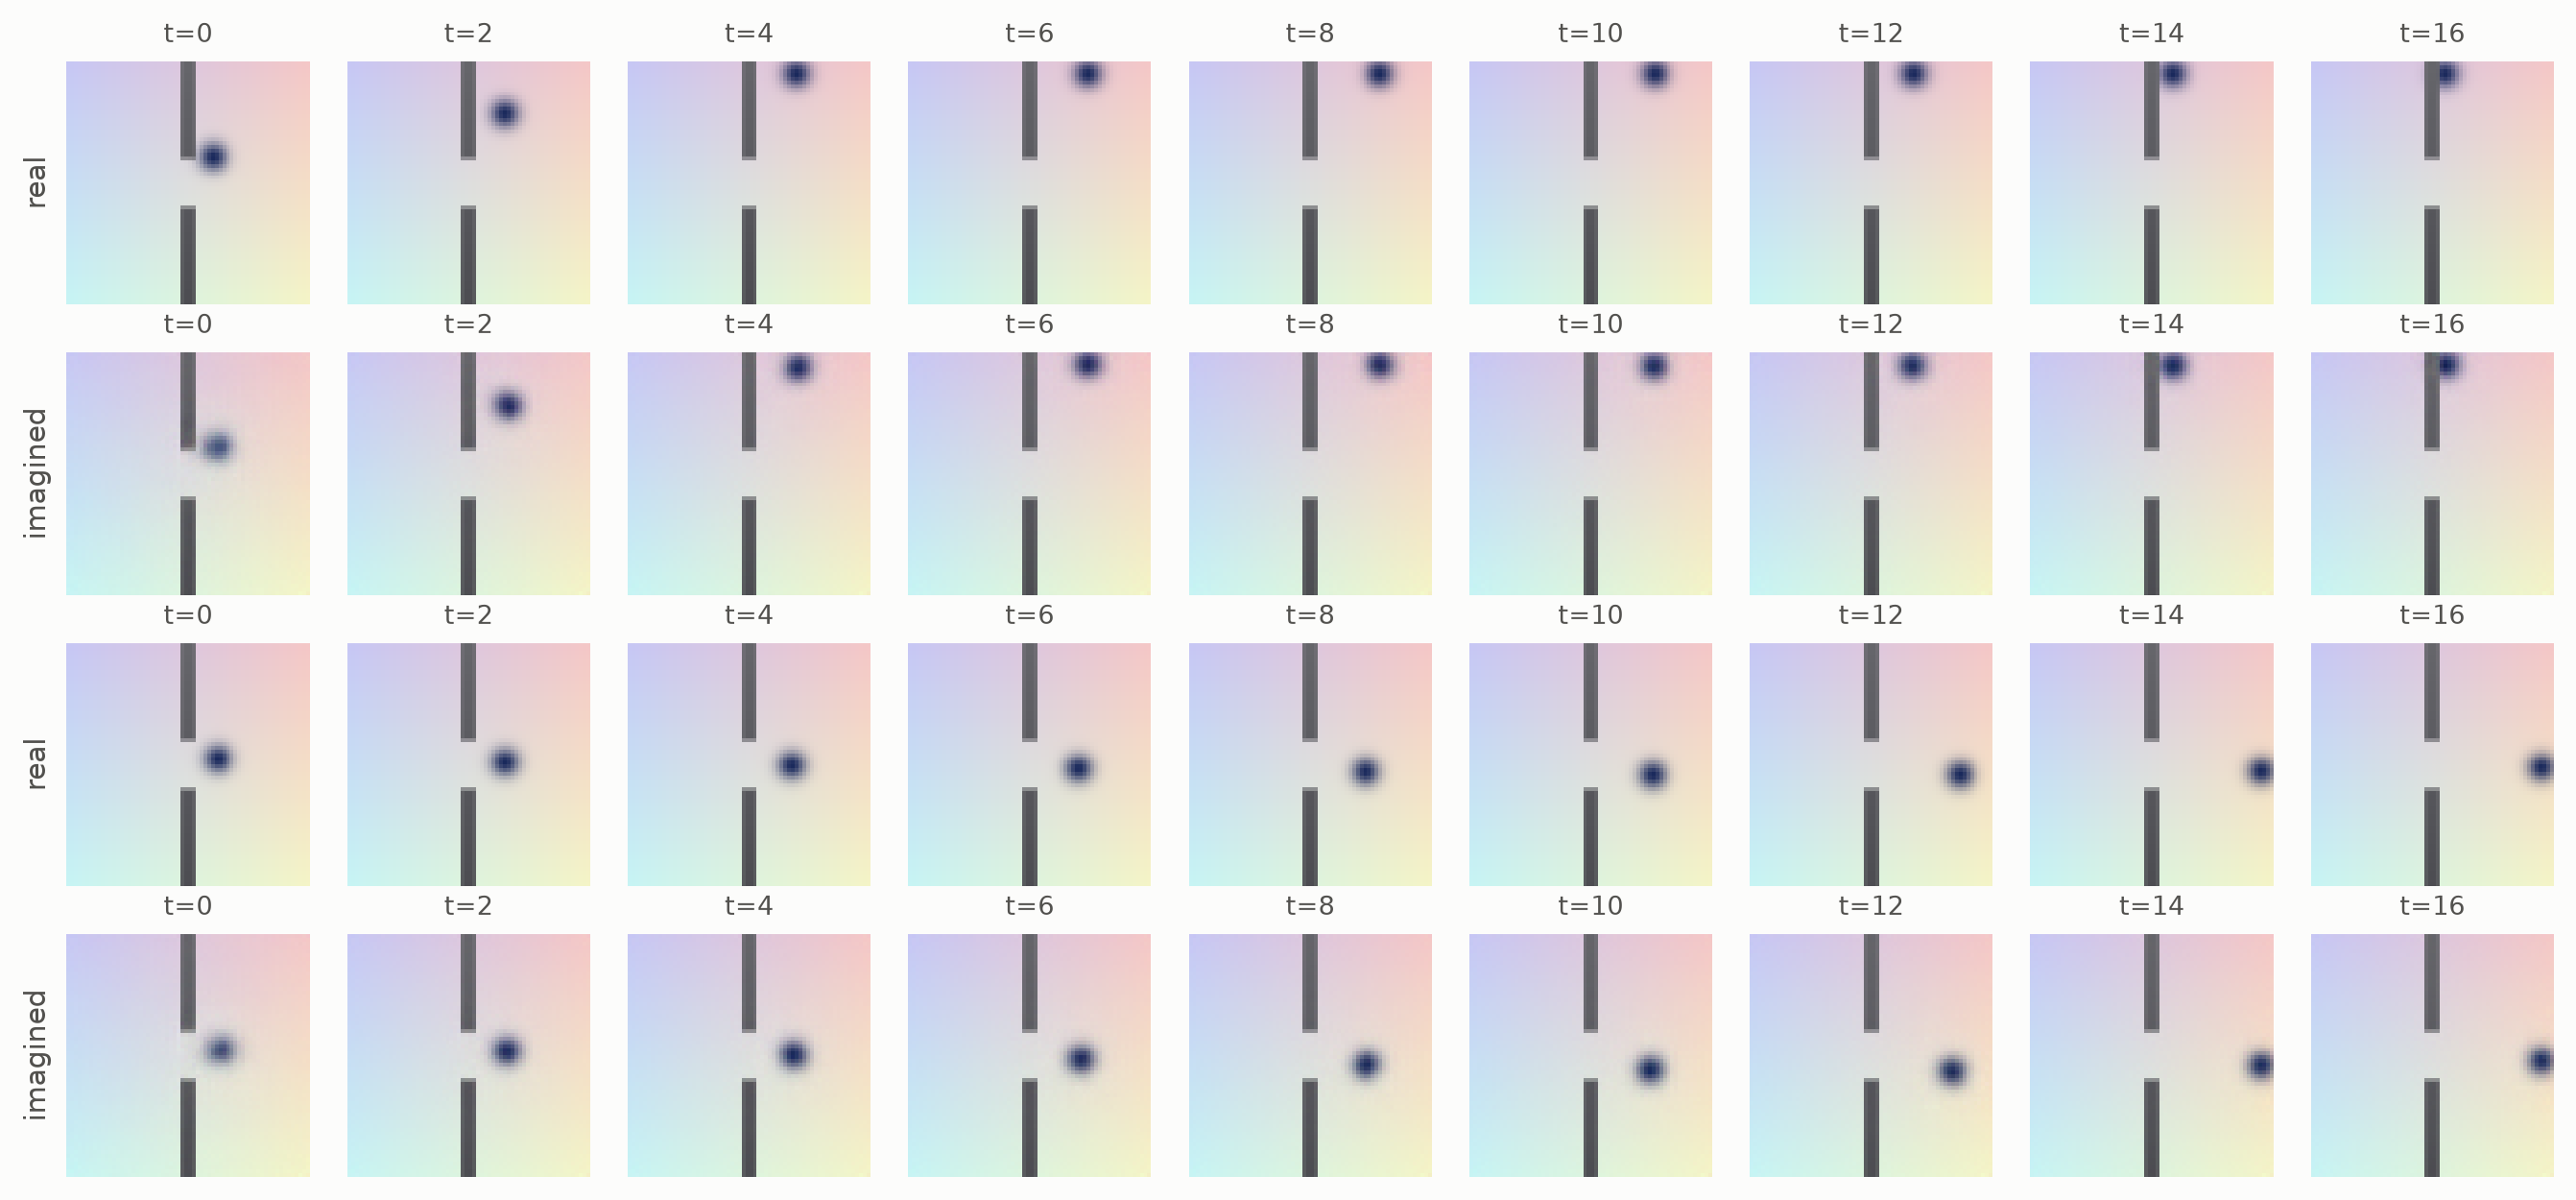

In [5]:
test = TwoRooms(batch_size=4, device=device).collect(17, generator=torch.Generator().manual_seed(2))
with torch.no_grad():
    z = model.encode(test["pixels"][:, :1])
    imagined = model.decode(model.rollout(z, test["actions"][:, :16])).clamp(0, 1)
steps = list(range(0, 17, 2))
error = (imagined - test["pixels"]).square().mean((0, 2, 3, 4))
print("pixel MSE per imagined step:", " ".join(f"{e:.4f}" for e in error.tolist()))
frames = torch.stack([test["pixels"][:2, steps], imagined[:2, steps]], 1).flatten(0, 2).cpu()  # (2 episodes x 2 rows x 9)
plots.images(frames, [f"t={t}" for t in steps] * 4, ncols=len(steps), rows=["real", "imagined"] * 2)

## Plan toward goal images
CEM searches 8-step action sequences in the model and scores each by the mean distance along its imagined path to the encoded goal image; the first action runs and the planner replans every step (the protocol of the main benchmark). The distance is taken on the whole model state, recurrent and stochastic parts (`cost_on="full"`, the default; in a 4-epoch tuning run it planned as well as or better than the stochastic part alone, and the recurrent part alone was worst). 32 tasks with the goal in the same room and 32 with the goal in the other room, 60 steps each; success is coming within 0.1 of the goal at any step, with 95% Wilson intervals.

In [6]:
cem = CEM(horizon=8, action_dim=2, num_samples=128, num_elites=16, iterations=5, bounds=(-1, 1), objective="path")
env = TwoRooms(batch_size=32, device=device)
tasks = {name: env.tasks(torch.Generator().manual_seed(1), same_room=same) for name, same in [("same room", True), ("other room", False)]}

results = {}
for name, (start, goal) in tasks.items():
    policies = {"DreamerV3 + CEM": evaluation.goal_policy(model, cem, env.render(goal)), "random actions": evaluation.random_policy(env)}
    results[name] = evaluation.goal_reaching(env, policies, start, goal, steps=60, success="reached")
    print(f"== {name}\n{results[name]}")

== same room
                           success  reached   steps  final distance  progress     SPL  smoothness  ms / step
DreamerV3 + CEM     94% [80%, 98%]      94%    3.47           0.023     0.933   0.202       0.592        189
random actions      59% [42%, 74%]      59%    16.5           0.289   -0.0157  0.0355        1.04     0.0808


== other room
                           success  reached   steps  final distance  progress     SPL  smoothness  ms / step
DreamerV3 + CEM      16% [7%, 32%]      16%    12.2           0.565     0.162  0.0395       0.962        188
random actions        3% [1%, 16%]       3%       7           0.651    -0.071 0.00228        1.04      0.033


## The actor, on hindsight goals
Dreamer's own way to act is its actor, learned in imagination from rewards. Two-Rooms has none, so a second model gets goals by hindsight, as TD-MPC2 does in the main benchmark: its input is the frame and a goal image stacked on channels, the goal is the last frame of the window or of another window, and the reward is minus the distance to the goal. The actor and critic train alongside the world model with the paper's settings, and the actor then acts alone, tracking the model state with `step`, with no search.

45.4 min


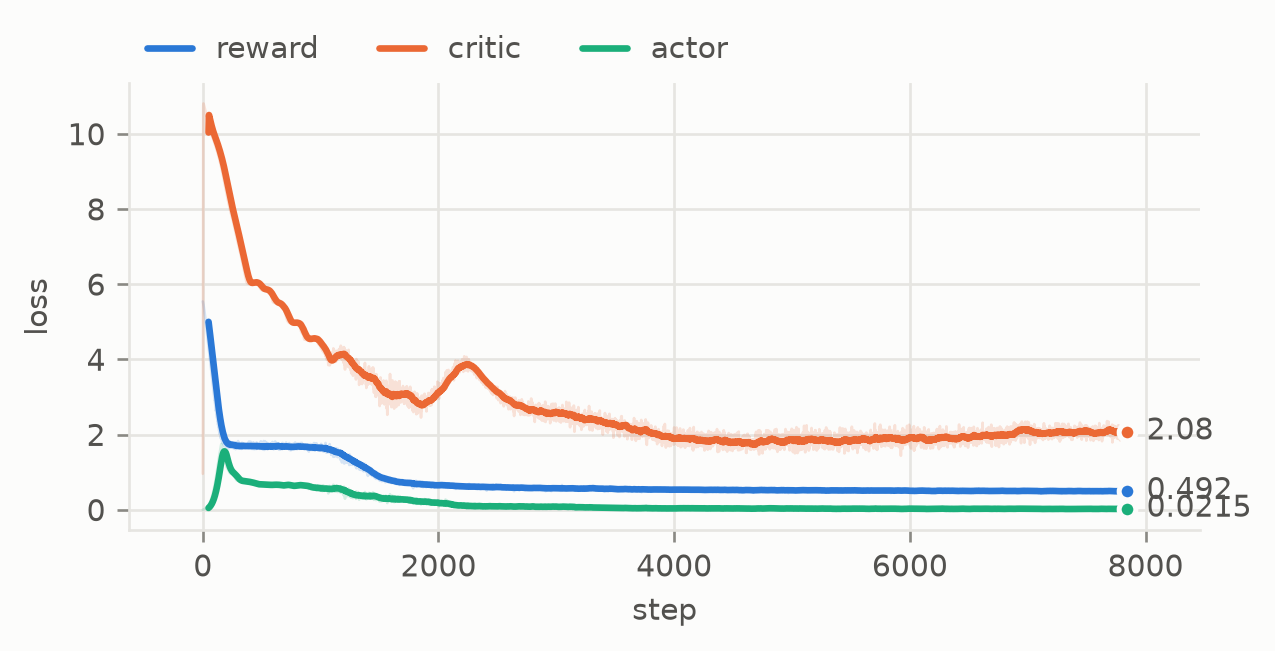

In [7]:
def hindsight(batch):
    pixels, states = batch["pixels"], batch["states"]  # (B, 17, ...)
    B = len(pixels)
    same = torch.rand(B, device=device) < 0.5
    other = torch.where(same, torch.arange(B, device=device), torch.randperm(B, device=device))
    goal_pixels, goal_states = pixels[other, -1], states[other, -1]
    obs = torch.cat([pixels, goal_pixels[:, None].expand_as(pixels)], dim=2)
    rewards = -(states[:, 1:] - goal_states[:, None]).norm(dim=-1)
    return obs, batch["actions"][:, :-1], rewards


agent = DreamerV3(action_dim=2, in_channels=6).to(device)
tic = time.time()
agent_log = train(agent, EPOCHS, hindsight)
agent.eval()
print(f"{(time.time() - tic) / 60:.1f} min")
plots.curves({k: agent_log[k] for k in ["reward", "critic", "actor"]}, smooth=50, logy=False)

In [8]:
class Actor:  # closed loop: filter the model state with each new frame, take the actor's mean action
    def __init__(self, model, goal_images):
        self.model, self.goal, self.state, self.action = model, goal_images, None, None

    @torch.no_grad()
    def __call__(self, obs):
        x = torch.cat([obs, self.goal], 1)
        self.state = self.model.encode(x[:, None])[:, 0] if self.state is None else self.model.step(self.state, self.action, x)
        self.action = self.model.act(self.state)
        return self.action


for name, (start, goal) in tasks.items():
    run = evaluation.goal_reaching(env, {"DreamerV3 actor": Actor(agent, env.render(goal))}, start, goal, steps=60, success="reached")
    for field, value in vars(run).items():  # add the actor's episodes to the CEM results
        if isinstance(value, dict):
            getattr(results[name], field).update(value)
    print(f"== {name}\n{results[name]}")

== same room
                           success  reached   steps  final distance  progress     SPL  smoothness  ms / step
DreamerV3 + CEM     94% [80%, 98%]      94%    3.47           0.023     0.933   0.202       0.592        189
random actions      59% [42%, 74%]      59%    16.5           0.289   -0.0157  0.0355        1.04     0.0808
DreamerV3 actor     75% [58%, 87%]      75%    5.46           0.197     0.429  0.0686         2.2       2.31


== other room
                           success  reached   steps  final distance  progress     SPL  smoothness  ms / step
DreamerV3 + CEM      16% [7%, 32%]      16%    12.2           0.565     0.162  0.0395       0.962        188
random actions        3% [1%, 16%]       3%       7           0.651    -0.071 0.00228        1.04      0.033
DreamerV3 actor     41% [26%, 58%]      41%    24.5           0.198     0.514  0.0743        2.11       4.13


## Summary

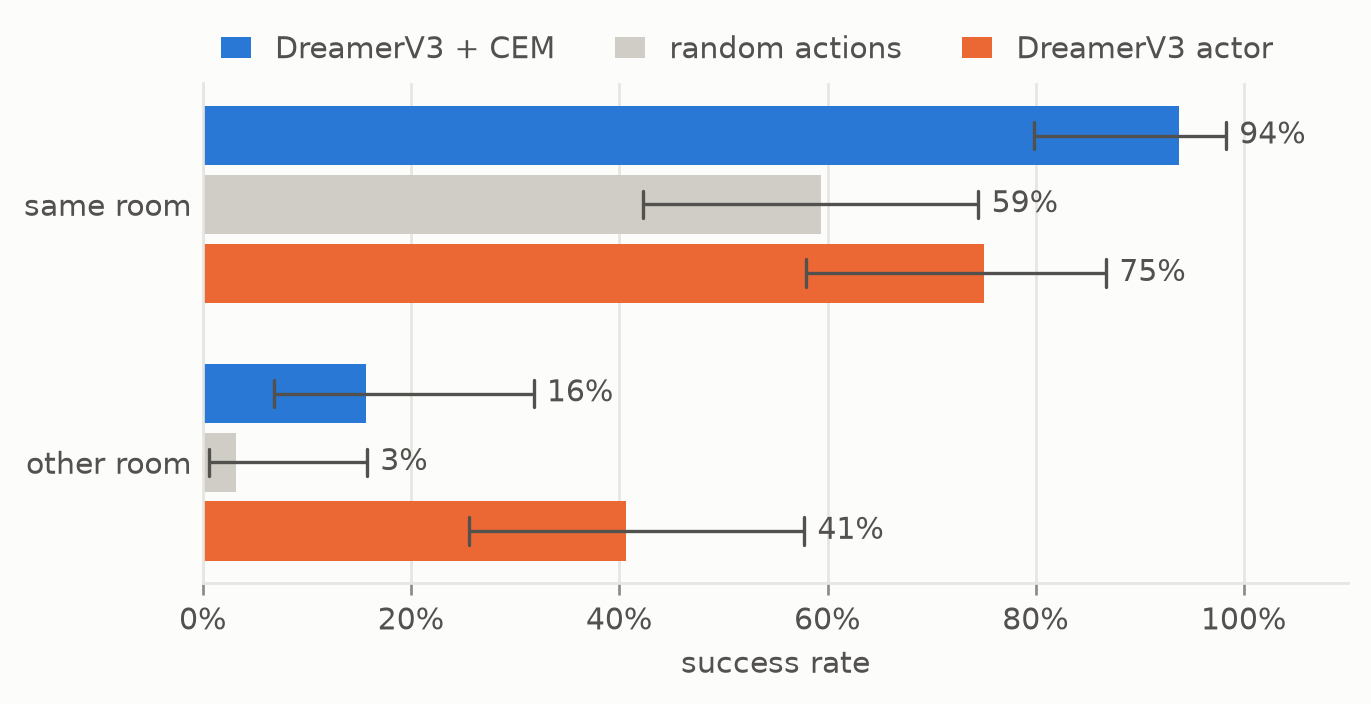

In [9]:
plots.bars({name: r.intervals() for name, r in results.items()}, xlabel="success rate", baseline="random actions")

DreamerV3 learns Two-Rooms from reward-free random-action episodes by reconstructing every frame. Its decoder shows what the model imagines: 16 steps open loop from one frame, the imagined point follows the real one, wall and all. That makes Dreamer the one world model in this library whose predictions can be checked by eye.

Planned with CEM on its model state, the reward-free model reaches same-room goals (94% [80%, 98%] against 59% for random actions) but rarely crosses the door (16% [7%, 32%], random 3%). That is the same pattern as LeWM and DINO-WM in the main benchmark: the latent distance to a goal in the other room does not point toward the door. Reconstruction spends most of the latent on the background, and the distance between model states is not built to measure progress toward a goal, the way PLDM's latent is.

The actor, trained in imagination on hindsight goals with the paper's settings, does better across the wall: 41% [26%, 58%] of other-room goals, against 16% for CEM, at 2 to 4 ms per step instead of about 190. It loses to CEM in the same room (75% [58%, 87%] vs 94%), and its paths are less direct (SPL 0.07 in both settings). The paper trains for far longer and at a much larger size (8M to 200M parameters) than these 10 epochs and 4.6M parameters, so these numbers say how the method behaves at notebook scale, not what DreamerV3 reaches.